# figure 5
re-analysis of proctor et al. 2018 maize yields (results from 5_proctor_regression)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
resid = pd.read_csv("results/proctor_residuals.csv", index_col="Year")
effects = pd.read_csv("results/proctor_effects.csv")
versions = [("Proctor et al. (2018)", "#f87666"), ("Area-weighted", "#c47900"),
            ("Area-weighted, southern Africa excluded", "#003466")]
names = [("tas", "Temperature"), ("saod", "Insolation"), ("clt", "Cloud"), ("pr", "Precipitation"), ("total", "Total")]

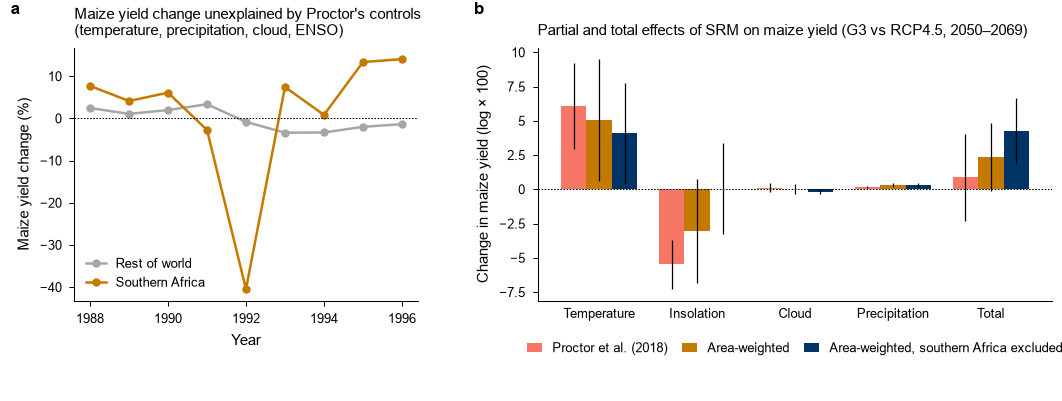

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(180 * mm, 68 * mm), gridspec_kw=dict(width_ratios=[0.8, 1.2]))
fig.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.25, wspace=0.28)

for g, col in (("Rest of world", "0.65"), ("Southern Africa", "#c47900")):
    a.plot(resid.index, 100 * (np.exp(resid[g]) - 1), marker="o", ms=3, lw=1.2, color=col, label=g)
a.axhline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)))
a.set_xticks(range(1988, 1997, 2)); a.set_xlabel("Year"); a.set_ylabel("Maize yield change (%)")
a.set_title("Maize yield change unexplained by Proctor's controls\n(temperature, precipitation, cloud, ENSO)")
a.legend(loc="lower left", handlelength=1.6)
a.yaxis.set_major_formatter(minus)

x = np.arange(len(names))
for j, (version, col) in enumerate(versions):
    s = effects[effects.version == version].set_index("effect").loc[[k for k, _ in names]]
    b.bar(x + (j - 1) * 0.26, s.value, 0.26, color=col, lw=0, label=version)
    b.vlines(x + (j - 1) * 0.26, s.value - s.ci95, s.value + s.ci95, color="black", lw=0.6)
b.axhline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)))
b.set_xticks(x); b.set_xticklabels([n for _, n in names]); b.tick_params(axis="x", length=0)
b.set_ylabel("Change in maize yield (log × 100)")
b.set_title("Partial and total effects of SRM on maize yield (G3 vs RCP4.5, 2050–2069)")
b.yaxis.set_major_formatter(minus)
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, handlelength=1.2, columnspacing=1.2)

for ax, letter in ((a, "a"), (b, "b")):
    p = ax.get_position()
    fig.text(p.x0 - 0.06, p.y1 + 0.075, letter, fontsize=8, fontweight="bold", va="bottom")
fig.savefig("figures/fig5_proctor.png", dpi=600)